# (old) Шаг 2. Топология остатка (.itp) при помощи acpype
*Путь словарей и тримеров (запись прежнего способа). Новый путь: `pt.run_acpype` в `2_forcefield.ipynb`.*

- **Вход** - 3D-структура шага 4.1 `molecules/substructure/<PTM_name>_rn_H_3D.pdb`: остаток с протонами `HW`
  на N и C (acpype не принимает оборванные валентности) и стереохимией CA - L.
- **Выход** - `Acpype_data/<PTM_name>_rn_H_3D.acpype/<PTM_name>_rn_H_3D_mod.itp`: типы атомов amber и параметры
  связей, углов, диэдралов; имена атомов и имя остатка - как в rtp. Дальше - `3_edd_topology_old.ipynb`.
- Ядро - окружение с acpype и parmed (`topmol2`).

*Важный момент: acpype готов принимать в себя только единичные остатки аминокислот. При попытке параметризовать ди-/три-/поли-мер выводит следующие ошибки:*\
`ERROR: more than one residue detected '{'UNK', 'GLY'}'` \
`ERROR: verify your input file 'GRG_CITsmi.mol2'. Aborting ...`\
`ERROR: Only ONE Residue is allowed for ACPYPE to work`

In [1]:
%load_ext autoreload
%autoreload 2
import sys
import os
ROOT_DIR = globals().get('ROOT_DIR') or os.path.abspath('..')  # notebooks_and_examples/
sys.path.append(ROOT_DIR)

from rdkit import Chem
from rdkit.Chem.Draw import IPythonConsole
from acpype.topol import ACTopol
from parmed import gromacs
import ResParTools as pt

IPythonConsole.ipython_useSVG = True
IPythonConsole.molSize = (600, 400)

In [2]:
# Параметры модификации
PTM_name = 'Lysine_3M'   # имя модификации: вход {PTM_name}_rn_H_3D.pdb (шаг 4.1)
base_name = 'K3M'        # имя остатка в силовом поле (как в rtp)
charge_val = None        # заряд для acpype вручную (на всякий случай); None - формальный заряд молекулы

## Вход: 3D-структура шага 4.1
Заряд для acpype (`chargeVal`) берётся из молекулы (сумма формальных зарядов), а не вписывается руками:
раньше он копировался между папками и местами был неверным (у нейтральных остатков стояло 1 и -3).

Lysine_3M_rn_H_3D: атомов 33, заряд +1


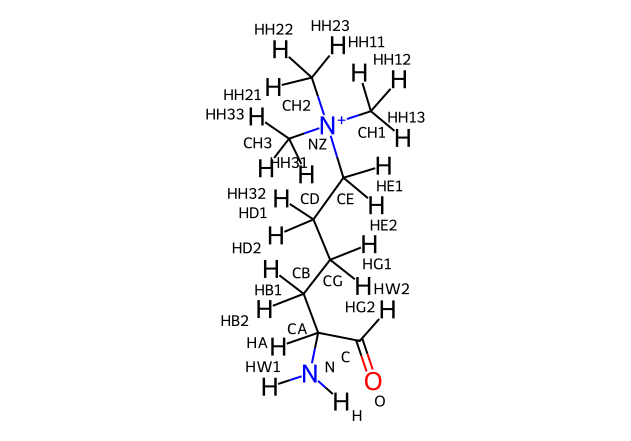

In [3]:
os.chdir(f'{ROOT_DIR}/{PTM_name}')
full_mol_name = f'{PTM_name}_rn_H_3D'
path = f'molecules/substructure/{full_mol_name}.pdb'
residue = pt.pdb_to_chem(path, format_coord='3D')[full_mol_name]
net_charge = Chem.GetFormalCharge(residue)
if charge_val is not None and charge_val != net_charge:
    pt.print_red(f'⚠ charge_val={charge_val:+d} не совпадает с зарядом молекулы {net_charge:+d}: acpype получит {charge_val:+d}')
    net_charge = charge_val
print(f'{full_mol_name}: атомов {residue.GetNumAtoms()}, заряд {net_charge:+d}')
pt.draw_molecule(residue, show_names=True, show_index=False)

## acpype
obabel переводит PDB в MDL (с порядками связей), acpype строит топологию: типы `amber`, заряды `gas`
(заряды acpype дальше не используются - их заменяют заряды Espaloma или RESP на шаге 3).

In [4]:
os.makedirs(f'{ROOT_DIR}/{PTM_name}/Acpype_data', exist_ok=True)
os.chdir(f'{ROOT_DIR}/{PTM_name}/Acpype_data')
!obabel ../{path} -O ../molecules/substructure/{full_mol_name}.mdl
molecule = ACTopol(inputFile=f'../molecules/substructure/{full_mol_name}.mdl',
                   chargeType='gas', atomType='amber', outTopol='gmx',
                   basename=full_mol_name, chargeVal=net_charge,
                   force=True)  # пересчитать заново: иначе acpype берёт старые файлы из <имя>.acpype/
molecule.createACTopol()
molecule.createMolTopol()

1 molecule converted


==> ... charge set to 1


==> Executing Antechamber...


==> * Antechamber OK *


==> * Parmchk OK *


...

==> Writing GROMACS files



==> Disambiguating lower and uppercase atomtypes in GMX top file, even if identical.



==> Writing GMX dihedrals for GMX 4.5 and higher.



==> Overwriting pickle file Lysine_3M_rn_H_3D.pkl


==> Removing temporary files...


## Имена атомов и остатка в itp
parmed переносит имена атомов из PDB в itp по порядку атомов. Перед этим порядок проверяется: элемент
каждого атома itp (по массе) должен совпасть с элементом атома PDB - иначе obabel или acpype переставили
атомы, и имена достались бы не тем атомам.

In [5]:
top_L = gromacs.GromacsTopologyFile(f'{full_mol_name}.acpype/{full_mol_name}_GMX.itp')
table = Chem.GetPeriodicTable()
if len(top_L.atoms) != residue.GetNumAtoms():
    raise ValueError(f'В itp {len(top_L.atoms)} атомов, в PDB {residue.GetNumAtoms()}')
wrong = [(a.GetIdx(), a.GetSymbol(), t.mass) for t, a in zip(top_L.atoms, residue.GetAtoms())
         if abs(table.GetAtomicWeight(a.GetSymbol()) - t.mass) > 0.1]
if wrong:
    raise ValueError(f'Порядок атомов itp не совпадает с PDB (индекс, элемент, масса в itp): {wrong[:5]}')
for top_atom, chem_atom in zip(top_L.atoms, residue.GetAtoms()):
    top_atom.name = chem_atom.GetProp('AtomName')
    top_atom.residue.name = base_name
top_L.save(f'{full_mol_name}.acpype/{full_mol_name}_mod.itp', format='gromacs', overwrite=True)
print(f'{full_mol_name}_mod.itp: атомов {len(top_L.atoms)}, остаток {base_name}')
print(' '.join(f'{a.name}:{a.type}' for a in top_L.atoms))

Lysine_3M_rn_H_3D_mod.itp: атомов 33, остаток K3M
N:NT H:H CA:CT HA:H1 CB:CT HB1:HC HB2:HC CG:CT HG1:HC HG2:HC CD:CT HD1:HC HD2:HC CE:CT HE1:HP HE2:HP NZ:N3 CH1:CT HH11:HP HH12:HP HH13:HP CH2:CT HH21:HP HH22:HP HH23:HP CH3:CT HH31:HP HH32:HP HH33:HP C:C O:O HW1:H HW2:HA
